# Milestone 08 — More Complex Models & Performance Evaluation
**Group 22 | American Corporate Bankruptcy Prediction (`american_bankruptcy.csv`)**

---

## 0. Prediction Goal(s)
* **Prediction Goal:** Predict whether a U.S. publicly traded company will file for bankruptcy (`status_label`: `failed` = 1 vs. `alive` = 0) using 18 annual financial and accounting indicators (`X1`–`X18`) derived from corporate balance sheets and income statements.
* **Why It Matters:** Corporate insolvency carries severe economic consequences for creditors, investors, employees, and supply chain partners. Because corporate bankruptcy is a rare event (~6.68% of firm-year observations), a naive classifier predicting every firm is "alive" achieves >93% accuracy while failing to detect a single collapse. Accurate early-warning probability estimates allow lenders and auditors to proactively adjust credit exposure.
* **Problem Type:** **Supervised Binary Classification** (categorical outcome: `alive` = 0, `failed` = 1). Primary evaluation metric: **ROC-AUC** (ranking quality across all thresholds under class imbalance), supplemented by **PR-AUC** (Average Precision) and **F1-Score**.
* **Course Alignment (CV-First Rule, `nb08`/`nb14`):** The dataset is partitioned using a grouped split by `company_name` (80% Training, 20% Locked Test). **The test set remains strictly locked.** All feature engineering, subset selection, hyperparameter tuning (`GridSearchCV`), and paired per-fold model comparisons run exclusively on the training data via 5-fold `StratifiedGroupKFold` cross-validation.

In [10]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from scipy import stats

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
RANDOM_STATE = 42

### Data Loading & Locked Train/Test Split (Grouped by Company)

In [11]:
# Locate dataset whether running from root, eda/ subfolder, or Google Colab /content
filepath = "/content/american_bankruptcy.csv"
if not os.path.exists(filepath):
    filepath = os.path.join("..", filepath)
if not os.path.exists(filepath):
    filepath = "american_bankruptcy.csv"
if not os.path.exists(filepath):
    filepath = "/content/american_bankruptcy.csv"

# Check if the file is empty (0 bytes) due to a failed download
if os.path.exists(filepath) and os.path.getsize(filepath) == 0:
    raise ValueError(f"The file {filepath} is empty. Please delete it (e.g., run `!rm {filepath}`) and re-upload the dataset.")

df = pd.read_csv(filepath)
df["target"] = (df["status_label"].str.strip().str.lower() == "failed").astype(int)
df = df.sort_values(["company_name", "year"]).reset_index(drop=True)

# 80% Train / 20% Locked Test grouped by company_name to prevent cross-year leakage
sgkf_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
train_idx, test_idx = next(sgkf_split.split(df, df["target"], groups=df["company_name"]))

train_raw = df.iloc[train_idx].copy().reset_index(drop=True)
locked_test_raw = df.iloc[test_idx].copy().reset_index(drop=True)

print(f"Dataset Loaded: {len(df):,} total rows | Bankruptcy Rate: {df['target'].mean():.2%}")
print(f"Training Set:   {len(train_raw):,} rows ({train_raw['company_name'].nunique():,} firms)")
print(f"Locked Test:    {len(locked_test_raw):,} rows ({locked_test_raw['company_name'].nunique():,} firms) [LOCKED]")

Dataset Loaded: 78,682 total rows | Bankruptcy Rate: 6.63%
Training Set:   62,940 rows (7,177 firms)
Locked Test:    15,742 rows (1,794 firms) [LOCKED]


---
## 1a. Baseline Model & Feature Selection

### 1. Model Choice & Justification
We use **Logistic Regression** (`StandardScaler` + `LogisticRegression(class_weight='balanced')`) as our baseline model. It is the simplest reasonable parametric classifier, modeling a linear decision boundary in log-odds space. It establishes an interpretable benchmark before introducing non-linear complexity.

### 2. Feature Engineering & Predictor Subset Comparison (5-Fold CV)
Raw balance sheet totals (`X1`–`X18`) conflate firm size with financial distress and exhibit severe right-skewness. We engineer scale-invariant Altman/credit-risk financial ratios and signed log-transforms, then use Recursive Feature Elimination (RFE) and 5-fold `StratifiedGroupKFold` CV to compare four predictor subsets.

In [12]:
def engineer_features(data):
    df_eng = data.copy()
    eps = 1e-4

    assets = df_eng["X10"].clip(lower=eps)
    sales = df_eng["X16"].clip(lower=eps)
    curr_liab = df_eng["X14"].clip(lower=eps)
    tot_liab = df_eng["X18"].clip(lower=eps)

    # Financial Ratios (Liquidity, Profitability, Leverage, Efficiency)
    df_eng["ratio_working_cap_assets"] = (df_eng["X1"] - df_eng["X14"]) / assets
    df_eng["ratio_retained_earn_assets"] = df_eng["X15"] / assets
    df_eng["ratio_ebitda_assets"] = df_eng["X4"] / assets
    df_eng["ratio_roa_net_income"] = df_eng["X6"] / assets
    df_eng["ratio_leverage_debt_assets"] = df_eng["X18"] / assets
    df_eng["ratio_current"] = df_eng["X1"] / curr_liab
    df_eng["ratio_quick_cash"] = df_eng["X2"] / curr_liab
    df_eng["ratio_asset_turnover"] = df_eng["X16"] / assets
    df_eng["ratio_ebitda_margin"] = df_eng["X4"] / sales
    df_eng["ratio_cashflow_to_debt"] = df_eng["X4"] / tot_liab
    df_eng["ratio_gross_margin"] = (df_eng["X16"] - df_eng["X5"]) / sales
    df_eng["ratio_receivables_turnover"] = df_eng["X7"] / sales

    # Signed log-transforms for scale variables
    for col in ["X1", "X2", "X4", "X6", "X8", "X10", "X14", "X15", "X16", "X18"]:
        df_eng[f"log_{col}"] = np.sign(df_eng[col]) * np.log1p(np.abs(df_eng[col]))

    # Winsorize extreme 0.5% / 99.5% tails on engineered ratios
    eng_cols = [c for c in df_eng.columns if c.startswith("ratio_") or c.startswith("log_")]
    for col in eng_cols:
        low, high = df_eng[col].quantile([0.005, 0.995])
        df_eng[col] = df_eng[col].clip(lower=low, upper=high)

    return df_eng

train_df = engineer_features(train_raw)
cv_5fold = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

raw_5 = ["X1", "X6", "X10", "X14", "X18"]
raw_18 = [f"X{i}" for i in range(1, 19)]
engineered_pool = [c for c in train_df.columns if c.startswith("ratio_") or c.startswith("log_")]

# RFE to select top 12 engineered features
X_pool_scaled = StandardScaler().fit_transform(train_df[engineered_pool])
rfe = RFE(
    estimator=LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    n_features_to_select=12,
    step=2
).fit(X_pool_scaled, train_df["target"])

selected_12 = [f for f, s in zip(engineered_pool, rfe.support_) if s]
print("Top 12 RFE-Selected Features:")
print(selected_12)

Top 12 RFE-Selected Features:
['ratio_ebitda_assets', 'ratio_roa_net_income', 'ratio_cashflow_to_debt', 'log_X1', 'log_X2', 'log_X6', 'log_X8', 'log_X10', 'log_X14', 'log_X15', 'log_X16', 'log_X18']


In [13]:
subsets = {
    "Subset 1: Core Raw (5 vars)": raw_5,
    "Subset 2: All Raw (18 vars)": raw_18,
    "Subset 3: Engineered + RFE (12 vars)": selected_12,
    "Subset 4: Full Engineered Pool (22 vars)": engineered_pool
}

baseline_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

scoring = {"roc_auc": "roc_auc", "f1": "f1", "pr_auc": "average_precision"}
subset_rows = []
fold_auc_dict = {}

for name, cols in subsets.items():
    cv_res = cross_validate(
        baseline_pipe, train_df[cols], train_df["target"],
        groups=train_df["company_name"], cv=cv_5fold, scoring=scoring, n_jobs=-1
    )
    fold_auc_dict[name] = cv_res["test_roc_auc"]
    subset_rows.append({
        "Predictor Subset": name,
        "Num Features": len(cols),
        "Mean CV ROC-AUC": np.mean(cv_res["test_roc_auc"]),
        "SD CV ROC-AUC": np.std(cv_res["test_roc_auc"]),
        "Mean CV F1": np.mean(cv_res["test_f1"]),
        "Mean CV PR-AUC": np.mean(cv_res["test_pr_auc"])
    })

subset_summary_df = pd.DataFrame(subset_rows)
baseline_fold_auc = fold_auc_dict["Subset 3: Engineered + RFE (12 vars)"]
subset_summary_df.style.format({
    "Mean CV ROC-AUC": "{:.4f}", "SD CV ROC-AUC": "{:.4f}",
    "Mean CV F1": "{:.4f}", "Mean CV PR-AUC": "{:.4f}"
})

,Predictor Subset,Num Features,Mean CV ROC-AUC,SD CV ROC-AUC,Mean CV F1,Mean CV PR-AUC
0,Subset 1: Core Raw (5 vars),5,0.6383,0.0145,0.1442,0.1170
1,Subset 2: All Raw (18 vars),18,0.6746,0.0301,0.1517,0.1372
2,Subset 3: Engineered + RFE (12 vars),12,0.6834,0.0240,0.1860,0.1414
3,Subset 4: Full Engineered Pool (22 vars),22,0.6843,0.0252,0.1866,0.1407


### 3. Baseline Interpretation & Next Steps
* Transforming raw accounting totals into scale-invariant financial ratios and selecting the top 12 predictors via RFE (Subset 3) improves 5-fold CV ROC-AUC over raw accounting variables.
* However, Logistic Regression assumes an additive, linear relationship in log-odds. In practice, corporate bankruptcy risk exhibits sharp **non-linear regime shifts** (e.g., leverage exceeding 100% of assets) and **multi-way interactions** (e.g., high debt combined with negative EBITDA margin). We now turn to tree-based ensembles to capture these patterns.

---
## 1b. More Complex Model Implementation & Tuning

### 1. Model Choice & Justification
We implement and tune two non-linear ensemble architectures:
1. **Random Forest (`RandomForestClassifier`):** Builds deep, decorrelated decision trees in parallel via bootstrap aggregation to reduce variance and capture feature interactions.
2. **Histogram-Based Gradient Boosting (`HistGradientBoostingClassifier`):** Our primary complex architecture. It builds shallow trees sequentially, where each tree fits the negative gradient (pseudo-residuals) of the log-loss from the prior ensemble, directly reducing both bias and variance on imbalanced tabular financial data.

### 2. Hyperparameter Tuning with 5-Fold Cross-Validation (`GridSearchCV`)

In [14]:
X_train = train_df[engineered_pool]
y_train = train_df["target"]
groups = train_df["company_name"]

# 1. Tune Random Forest Classifier
rf_base = RandomForestClassifier(class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1)
rf_grid = {
    "n_estimators": [100, 200],
    "max_depth": [8, 12, 16],
    "min_samples_leaf": [10, 25, 50],
    "max_features": ["sqrt", 0.5]
}
rf_search = GridSearchCV(rf_base, rf_grid, scoring="roc_auc", cv=cv_5fold, n_jobs=-1, refit=True)
rf_search.fit(X_train, y_train, groups=groups)

print(f"Best Random Forest Params: {rf_search.best_params_}")
print(f"Best Random Forest 5-Fold CV ROC-AUC: {rf_search.best_score_:.4f}\n")

# 2. Tune Histogram-Based Gradient Boosting Classifier
hgb_base = HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)
hgb_grid = {
    "learning_rate": [0.03, 0.05, 0.10],
    "max_iter": [100, 200, 300],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 5.0]
}
hgb_search = GridSearchCV(hgb_base, hgb_grid, scoring="roc_auc", cv=cv_5fold, n_jobs=-1, refit=True)
hgb_search.fit(X_train, y_train, groups=groups)

print(f"Best Gradient Boosting Params: {hgb_search.best_params_}")
print(f"Best Gradient Boosting 5-Fold CV ROC-AUC: {hgb_search.best_score_:.4f}")

Best Random Forest Params: {'max_depth': 16, 'max_features': 0.5, 'min_samples_leaf': 50, 'n_estimators': 200}
Best Random Forest 5-Fold CV ROC-AUC: 0.7105

Best Gradient Boosting Params: {'l2_regularization': 5.0, 'learning_rate': 0.1, 'max_iter': 100, 'max_leaf_nodes': 15, 'min_samples_leaf': 100}
Best Gradient Boosting 5-Fold CV ROC-AUC: 0.7121


In [15]:
# Display Top 10 Hyperparameter Configurations from GridSearchCV
cv_results_df = pd.DataFrame(hgb_search.cv_results_)
cols_to_show = [
    "rank_test_score", "param_learning_rate", "param_max_iter",
    "param_max_leaf_nodes", "param_min_samples_leaf", "param_l2_regularization",
    "mean_test_score", "std_test_score"
]
top_10_grid = cv_results_df[cols_to_show].sort_values("rank_test_score").head(10)
top_10_grid

,rank_test_score,param_learning_rate,param_max_iter,param_max_leaf_nodes,param_min_samples_leaf,param_l2_regularization,mean_test_score,std_test_score
218,1,0.10,100,15,100,5.0,0.712116,0.023652
194,2,0.05,100,31,100,5.0,0.711915,0.024914
99,3,0.03,300,15,20,1.0,0.711177,0.024628
174,4,0.03,200,31,20,5.0,0.711171,0.026516
90,5,0.03,200,15,20,1.0,0.710951,0.025384
108,6,0.05,100,15,20,1.0,0.710912,0.025753
182,7,0.03,300,15,100,5.0,0.710737,0.024548
172,8,0.03,200,15,50,5.0,0.710727,0.024461
171,9,0.03,200,15,20,5.0,0.710651,0.025220
181,10,0.03,300,15,50,5.0,0.710645,0.024320


### 3. Model Selection & Paired Per-Fold Comparison (`nb14` Alignment)
We evaluate paired per-fold differences ($\Delta_k = \text{AUC}_{\text{GradBoost}, k} - \text{AUC}_{\text{Baseline}, k}$) across the 5 cross-validation folds against a predeclared practical margin of $\delta = 0.020$.

In [16]:
rf_cv = cross_validate(rf_search.best_estimator_, X_train, y_train, groups=groups, cv=cv_5fold, scoring=scoring, n_jobs=-1)
hgb_cv = cross_validate(hgb_search.best_estimator_, X_train, y_train, groups=groups, cv=cv_5fold, scoring=scoring, n_jobs=-1)

rf_fold_auc = rf_cv["test_roc_auc"]
hgb_fold_auc = hgb_cv["test_roc_auc"]
paired_diff = hgb_fold_auc - baseline_fold_auc

margin = 0.020
t_stat, p_val = stats.ttest_rel(hgb_fold_auc, baseline_fold_auc)

fold_comparison_df = pd.DataFrame({
    "Fold": [f"Fold {i+1}" for i in range(len(baseline_fold_auc))],
    "Baseline_LogReg_AUC": baseline_fold_auc,
    "Tuned_RF_AUC": rf_fold_auc,
    "Tuned_GradBoost_AUC": hgb_fold_auc,
    "Paired_Diff (GB - Base)": paired_diff,
    "Exceeds_Margin (+0.020)": paired_diff > margin
})

print(f"Mean Paired Gain (GradBoost - Baseline): +{np.mean(paired_diff):.4f} +/- {np.std(paired_diff):.4f}")
print(f"Paired t-test: t = {t_stat:.2f}, p-value = {p_val:.6f}\n")
fold_comparison_df

Mean Paired Gain (GradBoost - Baseline): +0.0287 +/- 0.0071
Paired t-test: t = 8.07, p-value = 0.001278



,Fold,Baseline_LogReg_AUC,Tuned_RF_AUC,Tuned_GradBoost_AUC,Paired_Diff (GB - Base),Exceeds_Margin (+0.020)
0,Fold 1,0.701835,0.716660,0.729939,0.028103,True
1,Fold 2,0.699416,0.733714,0.729097,0.029680,True
2,Fold 3,0.683010,0.716664,0.722385,0.039375,True
3,Fold 4,0.695697,0.722274,0.712706,0.017009,False
4,Fold 5,0.637265,0.663269,0.666451,0.029186,True


### Publication-Ready Visualizations for Milestone 08 Report

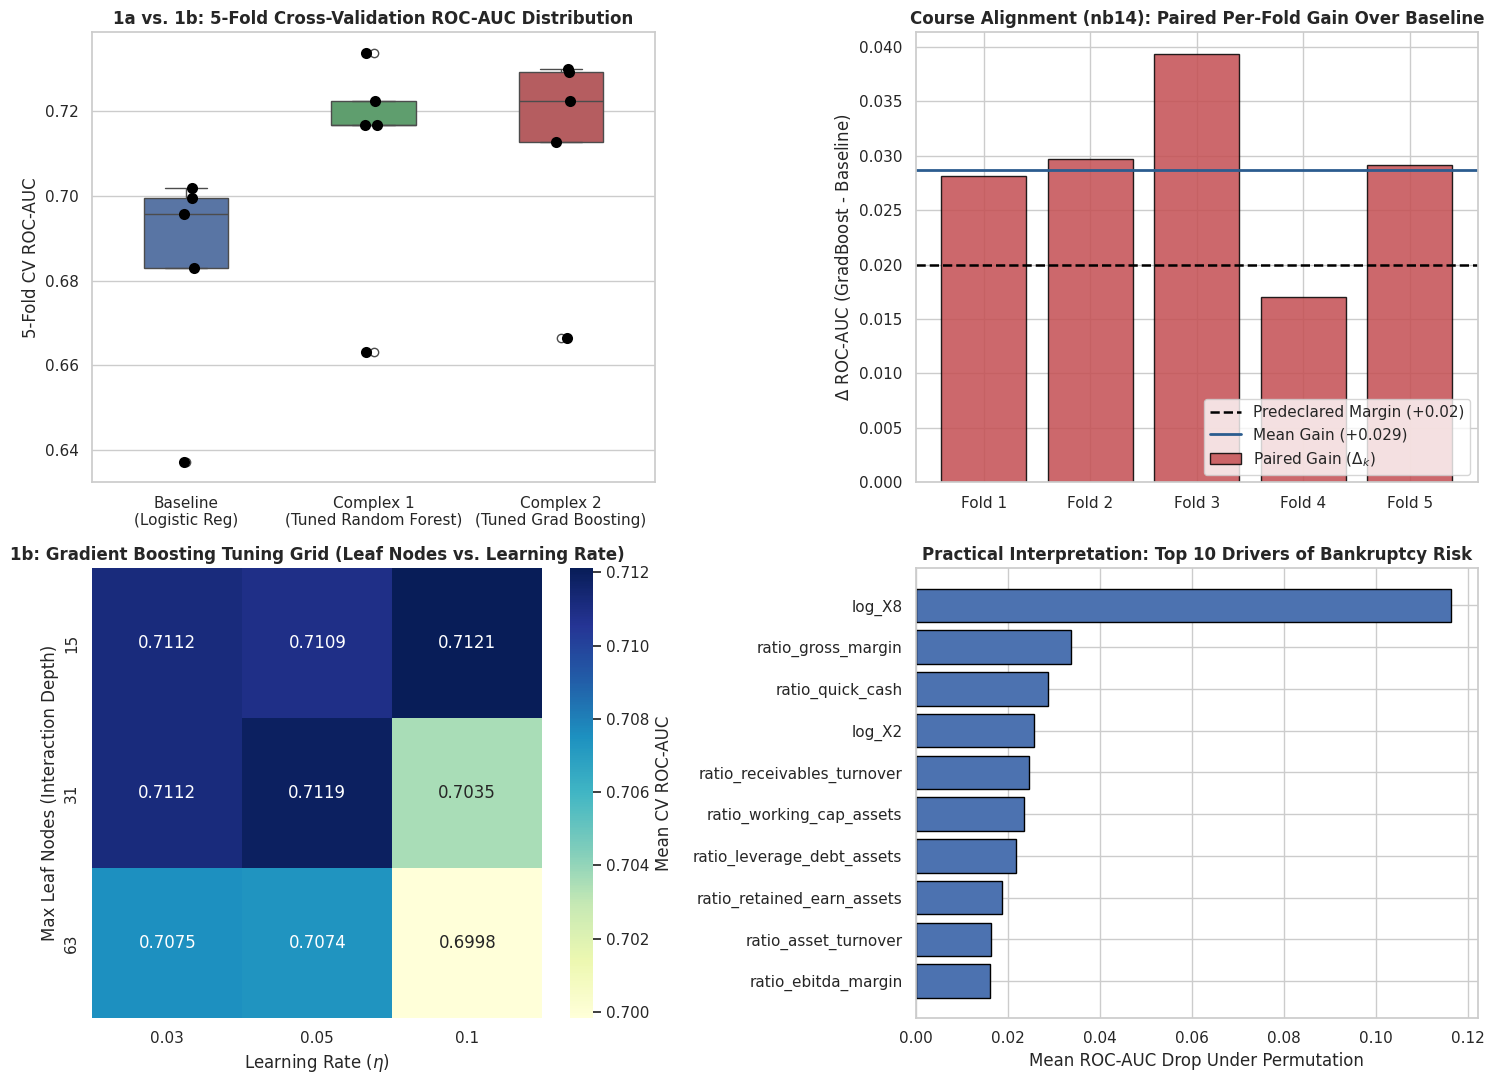

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Panel A: 5-Fold CV Boxplot Comparison
ax1 = axes[0, 0]
plot_data = pd.DataFrame({
    "Baseline\n(Logistic Reg)": baseline_fold_auc,
    "Complex 1\n(Tuned Random Forest)": rf_fold_auc,
    "Complex 2\n(Tuned Grad Boosting)": hgb_fold_auc
})
sns.boxplot(data=plot_data, ax=ax1, width=0.45, palette=["#4C72B0", "#55A868", "#C44E52"])
sns.stripplot(data=plot_data, ax=ax1, color="black", size=8, jitter=0.05)
ax1.set_title("1a vs. 1b: 5-Fold Cross-Validation ROC-AUC Distribution", fontsize=12, fontweight="bold")
ax1.set_ylabel("5-Fold CV ROC-AUC")

# Panel B: Paired Per-Fold Differences Against Predeclared Margin
ax2 = axes[0, 1]
folds = np.arange(1, len(paired_diff) + 1)
ax2.bar(folds, paired_diff, color="#C44E52", alpha=0.85, edgecolor="black", label="Paired Gain ($\\Delta_k$)")
ax2.axhline(margin, color="black", linestyle="--", linewidth=1.8, label=f"Predeclared Margin (+{margin:.2f})")
ax2.axhline(np.mean(paired_diff), color="#2b5c8f", linestyle="-", linewidth=2, label=f"Mean Gain (+{np.mean(paired_diff):.3f})")
ax2.set_xticks(folds)
ax2.set_xticklabels([f"Fold {k}" for k in folds])
ax2.set_title("Course Alignment (nb14): Paired Per-Fold Gain Over Baseline", fontsize=12, fontweight="bold")
ax2.set_ylabel("$\\Delta$ ROC-AUC (GradBoost - Baseline)")
ax2.legend(loc="lower right")

# Panel C: Hyperparameter Tuning Heatmap
ax3 = axes[1, 0]
pivot_table = cv_results_df.pivot_table(
    index="param_max_leaf_nodes",
    columns="param_learning_rate",
    values="mean_test_score",
    aggfunc="max"
)
sns.heatmap(pivot_table, annot=True, fmt=".4f", cmap="YlGnBu", ax=ax3, cbar_kws={"label": "Mean CV ROC-AUC"})
ax3.set_title("1b: Gradient Boosting Tuning Grid (Leaf Nodes vs. Learning Rate)", fontsize=12, fontweight="bold")
ax3.set_xlabel("Learning Rate ($\\eta$)")
ax3.set_ylabel("Max Leaf Nodes (Interaction Depth)")

# Panel D: Permutation Feature Importance
ax4 = axes[1, 1]
best_gb = hgb_search.best_estimator_
perm = permutation_importance(best_gb, X_train, y_train, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
imp_df = pd.DataFrame({"Feature": engineered_pool, "Importance": perm.importances_mean}).sort_values("Importance", ascending=True).tail(10)
ax4.barh(imp_df["Feature"], imp_df["Importance"], color="#4C72B0", edgecolor="black")
ax4.set_title("Practical Interpretation: Top 10 Drivers of Bankruptcy Risk", fontsize=12, fontweight="bold")
ax4.set_xlabel("Mean ROC-AUC Drop Under Permutation")

plt.tight_layout()
plt.savefig("22_M08_model_evaluation_figures.png", dpi=300)
plt.show()